# Colocate a synthetic glider with SWOT passages

This example creates a moving glider trajectory `(x, y, t)`, associates every observation with its closest nominal SWOT passage, and keeps the synthetic measurements alongside the colocation results.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

import pandas as pd
import numpy as np

SatPass version: 0.1.0


## Generate synthetic glider observations

Replace this table with real glider longitude, latitude, time, and measurement columns when available.

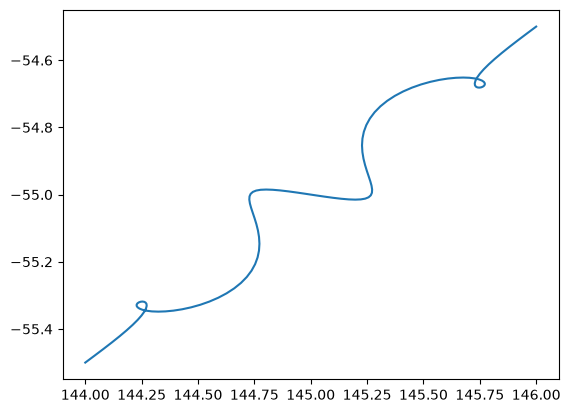

In [2]:
glider_time = pd.date_range("2026-07-01", "2026-07-31 18:00", freq="6h")
progress = np.linspace(0, 1, len(glider_time))

glider = pd.DataFrame(
    {
        "time": glider_time,
        "longitude": 144.0 + 2.0 * progress + 0.12 * np.sin(8 * np.pi * progress),
        "latitude": -55.5 + 1.0 * progress + 0.08 * np.sin(6 * np.pi * progress),
    }
)
plt.plot(glider.longitude, glider.latitude)

## Associate `(x, y, t)` with SWOT

`swot_time` is the predicted passage time and `time_offset_days = swot_time - observation_time`. A negative offset means SWOT passed before the glider observation.

In [3]:
glider_swot = satpass.colocate_xyt(
    x=glider["longitude"],
    y=glider["latitude"],
    t=glider["time"],
    n_passes=1,
    max_distance_km=65.0,
)

glider_swot

,longitude,latitude,observation_time,swot_time,time_offset_days,track,cycle,direction,distance_to_nadir_km
0,144.000000,-55.500000,2026-07-01 00:00:00,2026-06-27 19:48:00,-3.175000,239,52,asc,47.724746
1,144.040610,-55.479658,2026-07-01 06:00:00,2026-07-04 09:06:00,3.129167,422,52,des,36.331725
2,144.080206,-55.459602,2026-07-01 12:00:00,2026-07-04 09:06:00,2.879167,422,52,des,33.244140
3,144.117819,-55.440112,2026-07-01 18:00:00,2026-07-04 09:06:00,2.629167,422,52,des,30.292429
4,144.152559,-55.421454,2026-07-02 00:00:00,2026-07-04 09:06:00,2.379167,422,52,des,27.539504
...,...,...,...,...,...,...,...,...,...
119,145.847441,-54.578546,2026-07-30 18:00:00,2026-07-28 14:41:00,-2.138194,517,53,asc,46.557019
120,145.882181,-54.559888,2026-07-31 00:00:00,2026-07-28 14:41:00,-2.388194,517,53,asc,45.156970
121,145.919794,-54.540398,2026-07-31 06:00:00,2026-07-28 14:41:00,-2.638194,517,53,asc,43.611880
122,145.959390,-54.520342,2026-07-31 12:00:00,2026-07-28 14:41:00,-2.888194,517,53,asc,41.964595


## Map the trajectory and matched nominal tracks

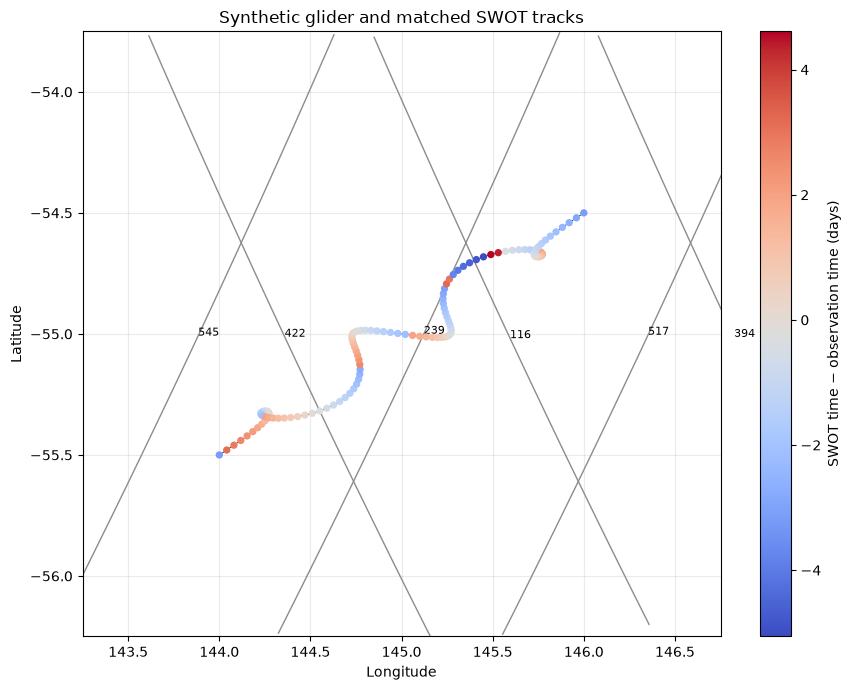

In [4]:
padding = 0.75
region = [
    glider["longitude"].min() - padding,
    glider["longitude"].max() + padding,
    glider["latitude"].min() - padding,
    glider["latitude"].max() + padding,
]
nominal = satpass.NominalTrack("sw")
tracks = nominal.select_in_area(region, extend_to_latitude_bounds=True)
matched_tracks = set(glider_swot["track"].dropna().astype(int))
tracks = tracks[tracks["track"].isin(matched_tracks)]

fig, ax = plt.subplots(figsize=(9, 7))
for track_number, track in tracks.groupby("track"):
    ax.plot(track["lon"], track["lat"], linewidth=1, color="0.55")
    midpoint = track.iloc[len(track) // 2]
    ax.text(midpoint["lon"], midpoint["lat"], str(track_number), fontsize=8)

points = ax.scatter(
    glider_swot["longitude"],
    glider_swot["latitude"],
    c=glider_swot["time_offset_days"],
    cmap="coolwarm",
    s=18,
    zorder=3,
)
ax.plot(glider_swot["longitude"], glider_swot["latitude"], color="k", linewidth=0.5)
ax.set(
    xlim=region[:2],
    ylim=region[2:],
    xlabel="Longitude",
    ylabel="Latitude",
    title="Synthetic glider and matched SWOT tracks",
)
ax.grid(alpha=0.25)
fig.colorbar(points, ax=ax, label="SWOT time − observation time (days)")
plt.tight_layout()